    # Faz 3 — Veri Hazırlama Kontrolü

Bu notebook, xBD veri hazırlama sürecinin Faz 3 çıktılarının doğrulanması için hazırlanmıştır.

Kontroller:

- Patch manifest bütünlüğü
- Train / Validation / Test dağılımları
- Hasar sınıfı dağılımları
- Split leakage kontrolü
- Patch ve padding örnekleri
- Dataset / DataLoader smoke testi
- SHA256 doğrulamaları
- Seed 42 ile deterministik patch kontrolü

In [1]:
from pathlib import Path
import sys
import hashlib
import random

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import transforms

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.constants import LABEL_MAP
from src.data.dataset import DamagePatchDataset, PairedRandomGeometric

MANIFEST = ROOT / "data" / "processed" / "patches_full" / "patches.csv"

print("Project root :", ROOT.name)
print("Manifest     :", MANIFEST.relative_to(ROOT))
print("Exists       :", MANIFEST.exists())
print("LABEL_MAP    :", LABEL_MAP)

Project root : disaster-damage-detection
Manifest     : data\processed\patches_full\patches.csv
Exists       : True
LABEL_MAP    : {'no-damage': 0, 'minor-damage': 1, 'major-damage': 2, 'destroyed': 3}


In [2]:
df = pd.read_csv(MANIFEST)

print("Manifest rows:", len(df))
print()

print("Split counts:")
print(df["split"].value_counts().sort_index())
print()

print("Columns:")
print(list(df.columns))

Manifest rows: 213449

Split counts:
split
test      53806
train    134028
val       25615
Name: count, dtype: int64

Columns:
['image_id', 'uid', 'disaster', 'damage', 'split', 'pre_patch', 'post_patch', 'x_min', 'y_min', 'x_max', 'y_max', 'patch_side', 'pad_left', 'pad_top', 'pad_right', 'pad_bottom']


## 1. Sınıf Dağılımları

Her split içerisindeki hasar sınıflarının dağılımı kontrol edilir.
`un-classified` örneklerin patch veri setinde bulunmaması beklenir.

In [3]:
class_distribution = pd.crosstab(
    df["damage"],
    df["split"],
    margins=True,
)

class_distribution

split,test,train,val,All
damage,,,,
destroyed,3775,10331,2887,16993
major-damage,3847,12064,2076,17987
minor-damage,4793,12060,2916,19769
no-damage,41391,99573,17736,158700
All,53806,134028,25615,213449


In [4]:
print("Damage labels:", sorted(df["damage"].unique()))
print("Un-classified count:", (df["damage"] == "un-classified").sum())

assert set(df["damage"].unique()) == set(LABEL_MAP.keys())
assert (df["damage"] == "un-classified").sum() == 0

print("Class label kontrolü: PASS")

Damage labels: ['destroyed', 'major-damage', 'minor-damage', 'no-damage']
Un-classified count: 0
Class label kontrolü: PASS


## 2. Split Leakage Kontrolü

Aynı `image_id` değerinin train, validation ve test splitleri arasında bulunup
bulunmadığı kontrol edilir.

Ayrıca `(split, image_id, uid)` anahtarında tekrar olup olmadığı incelenir.

In [5]:
train_ids = set(df.loc[df["split"] == "train", "image_id"])
val_ids = set(df.loc[df["split"] == "val", "image_id"])
test_ids = set(df.loc[df["split"] == "test", "image_id"])

train_val_overlap = train_ids & val_ids
train_test_overlap = train_ids & test_ids
val_test_overlap = val_ids & test_ids

duplicate_keys = df.duplicated(
    subset=["split", "image_id", "uid"]
).sum()

print("Train image_id:", len(train_ids))
print("Val image_id  :", len(val_ids))
print("Test image_id :", len(test_ids))
print()

print("Train-Val overlap :", len(train_val_overlap))
print("Train-Test overlap:", len(train_test_overlap))
print("Val-Test overlap  :", len(val_test_overlap))
print()

print("Duplicate (split, image_id, uid):", duplicate_keys)

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0
assert duplicate_keys == 0

print()
print("Split leakage kontrolü: PASS")

Train image_id: 1899
Val image_id  : 340
Test image_id : 739

Train-Val overlap : 0
Train-Test overlap: 0
Val-Test overlap  : 0

Duplicate (split, image_id, uid): 0

Split leakage kontrolü: PASS


## 3. Patch Boyutu ve Padding Kontrolü

Patch'lerin minimum kenar kuralına uyduğu ve görüntü sınırını aşan crop'larda
uygulanan siyah padding değerlerinin geçerli olduğu kontrol edilir.

In [6]:
pad_cols = [
    "pad_left",
    "pad_top",
    "pad_right",
    "pad_bottom",
]

has_padding = df[pad_cols].gt(0).any(axis=1)

print("Patch side minimum :", df["patch_side"].min())
print("Patch side maximum :", df["patch_side"].max())
print("Patch side median  :", df["patch_side"].median())
print()

print("Padding kullanılan çift :", int(has_padding.sum()))
print("Padding olmayan çift    :", int((~has_padding).sum()))
print()

print("Padding yönlerine göre:")
for col in pad_cols:
    print(f"{col:10s}: {(df[col] > 0).sum()}")

print()
print("Negative padding value:", int(df[pad_cols].lt(0).sum().sum()))
print("patch_side < 64       :", int((df["patch_side"] < 64).sum()))

assert df[pad_cols].lt(0).sum().sum() == 0
assert (df["patch_side"] < 64).sum() == 0

print()
print("Patch boyutu / padding kontrolü: PASS")

Patch side minimum : 64
Patch side maximum : 2045
Patch side median  : 74.0

Padding kullanılan çift : 42513
Padding olmayan çift    : 170936

Padding yönlerine göre:
pad_left  : 11470
pad_top   : 11723
pad_right : 10840
pad_bottom: 11023

Negative padding value: 0
patch_side < 64       : 0

Patch boyutu / padding kontrolü: PASS


## 4. Manifest SHA256 ve Dosya Yolu Bütünlüğü

Patch manifestinin SHA256 değeri hesaplanır ve manifestte listelenen PRE/POST
patch yollarının mevcut olduğu doğrulanır.

In [7]:
def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        while chunk := f.read(chunk_size):
            digest.update(chunk)

    return digest.hexdigest()


manifest_sha256 = sha256_file(MANIFEST)

EXPECTED_MANIFEST_SHA256 = (
    "383da7b841c0bd8b11b9cf807873b029291ad23b3c3f48135d9b7dde1ffe11ec"
)

print("Manifest SHA256 :", manifest_sha256)
print("Expected SHA256 :", EXPECTED_MANIFEST_SHA256)
print("Match           :", manifest_sha256 == EXPECTED_MANIFEST_SHA256)

assert manifest_sha256 == EXPECTED_MANIFEST_SHA256

print()
print("Manifest SHA256 kontrolü: PASS")

Manifest SHA256 : 383da7b841c0bd8b11b9cf807873b029291ad23b3c3f48135d9b7dde1ffe11ec
Expected SHA256 : 383da7b841c0bd8b11b9cf807873b029291ad23b3c3f48135d9b7dde1ffe11ec
Match           : True

Manifest SHA256 kontrolü: PASS


In [8]:
pre_paths = [ROOT / p for p in df["pre_patch"]]
post_paths = [ROOT / p for p in df["post_patch"]]

missing_pre = [p for p in pre_paths if not p.exists()]
missing_post = [p for p in post_paths if not p.exists()]

listed_paths = (
    df["pre_patch"].tolist()
    + df["post_patch"].tolist()
)

duplicate_listed_paths = (
    len(listed_paths) - len(set(listed_paths))
)

print("PRE paths         :", len(pre_paths))
print("POST paths        :", len(post_paths))
print("Total listed PNG  :", len(listed_paths))
print("Missing PRE       :", len(missing_pre))
print("Missing POST      :", len(missing_post))
print("Duplicate paths   :", duplicate_listed_paths)

assert len(missing_pre) == 0
assert len(missing_post) == 0
assert duplicate_listed_paths == 0

print()
print("Patch path bütünlüğü: PASS")

PRE paths         : 213449
POST paths        : 213449
Total listed PNG  : 426898
Missing PRE       : 0
Missing POST      : 0
Duplicate paths   : 0

Patch path bütünlüğü: PASS


## 5. Deterministik Patch Görsel Kontrolü

Seed 42 kullanılarak train/validation verisinden örnek patch çiftleri seçilir.
PRE ve POST görüntülerinin aynı yapıya ait crop çiftleri olduğu görsel olarak
kontrol edilir.

Challenge Test görüntüleri model geliştirme ve görsel tuning amacıyla kullanılmaz.

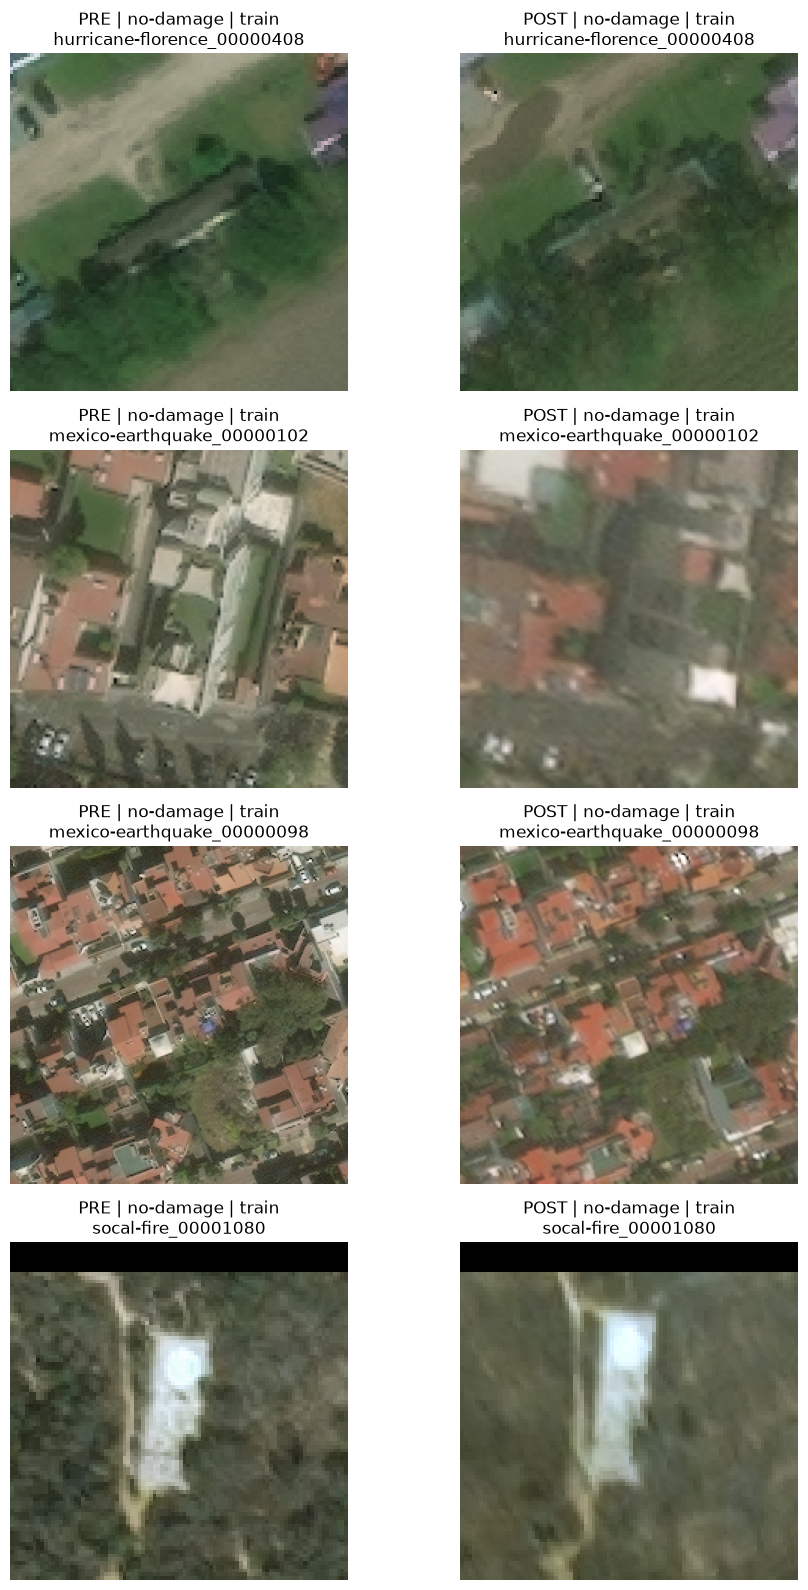

In [9]:
import matplotlib.pyplot as plt

sample_pool = df[df["split"].isin(["train", "val"])]

samples = (
    sample_pool
    .sample(n=4, random_state=42)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(10, 16),
)

for i, row in samples.iterrows():
    pre = Image.open(ROOT / row["pre_patch"]).convert("RGB")
    post = Image.open(ROOT / row["post_patch"]).convert("RGB")

    axes[i, 0].imshow(pre)
    axes[i, 0].set_title(
        f"PRE | {row['damage']} | {row['split']}\n"
        f"{row['image_id']}"
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(post)
    axes[i, 1].set_title(
        f"POST | {row['damage']} | {row['split']}\n"
        f"{row['image_id']}"
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

## 6. Dataset / DataLoader Smoke Test

Model giriş boyutu Dataset içerisine hard-code edilmez.
Resize dış transform ile uygulanır.

Train için paired geometrik augmentation aktiftir.
Validation için augmentation kapalıdır.
Windows uyumluluğu için smoke testte `num_workers=0` kullanılır.

In [10]:
resize_transform = transforms.Compose(
    [
        transforms.Resize((128, 128)),
        transforms.ToTensor(),
    ]
)

train_dataset = DamagePatchDataset(
    MANIFEST,
    split="train",
    paired_transform=PairedRandomGeometric(),
    transform=resize_transform,
    project_root=ROOT,
)

val_dataset = DamagePatchDataset(
    MANIFEST,
    split="val",
    paired_transform=None,
    transform=resize_transform,
    project_root=ROOT,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
)

train_batch = next(iter(train_loader))
val_batch = next(iter(val_loader))

print("TRAIN")
print("pre  :", train_batch["pre"].shape, train_batch["pre"].dtype)
print("post :", train_batch["post"].shape, train_batch["post"].dtype)
print("label:", train_batch["label"].shape, train_batch["label"].dtype)

print()
print("VAL")
print("pre  :", val_batch["pre"].shape, val_batch["pre"].dtype)
print("post :", val_batch["post"].shape, val_batch["post"].dtype)
print("label:", val_batch["label"].shape, val_batch["label"].dtype)

assert train_batch["pre"].shape == (4, 3, 128, 128)
assert train_batch["post"].shape == (4, 3, 128, 128)
assert train_batch["label"].shape == (4,)
assert train_batch["label"].dtype == torch.int64

assert val_batch["pre"].shape == (4, 3, 128, 128)
assert val_batch["post"].shape == (4, 3, 128, 128)
assert val_batch["label"].shape == (4,)
assert val_batch["label"].dtype == torch.int64

print()
print("Dataset / DataLoader smoke test: PASS")

TRAIN
pre  : torch.Size([4, 3, 128, 128]) torch.float32
post : torch.Size([4, 3, 128, 128]) torch.float32
label: torch.Size([4]) torch.int64

VAL
pre  : torch.Size([4, 3, 128, 128]) torch.float32
post : torch.Size([4, 3, 128, 128]) torch.float32
label: torch.Size([4]) torch.int64

Dataset / DataLoader smoke test: PASS


## 7. Seed 42 — Pixel Array SHA256 Doğrulaması

Train ve validation patch'lerinden deterministik olarak 20 görüntü seçilir.

Dosya byte'ları yerine görüntünün RGB pixel array'i SHA256 ile hashlenir.
Böylece farklı makinelerde aynı patch içeriğinin piksel seviyesinde birebir
aynı olup olmadığı doğrulanabilir.

Challenge Test bu doğrulama örneklemine dahil edilmez.

In [11]:
SEED = 42

metadata_cols = [
    "split",
    "disaster",
    "damage",
    "image_id",
    "uid",
]

dev_df = df[df["split"].isin(["train", "val"])].copy()

pre_candidates = dev_df[
    metadata_cols + ["pre_patch"]
].rename(
    columns={"pre_patch": "patch_path"}
)
pre_candidates["side"] = "pre"

post_candidates = dev_df[
    metadata_cols + ["post_patch"]
].rename(
    columns={"post_patch": "patch_path"}
)
post_candidates["side"] = "post"

candidates = pd.concat(
    [pre_candidates, post_candidates],
    ignore_index=True,
)

# Python / pandas random algoritmasına bağımlı kalmamak için
# seed değeri path ile birlikte SHA256 seçim anahtarına dönüştürülür.
candidates["selection_key"] = candidates["patch_path"].map(
    lambda p: hashlib.sha256(
        f"{SEED}|{p}".encode("utf-8")
    ).hexdigest()
)

selected = (
    candidates
    .sort_values(["selection_key", "patch_path"])
    .head(20)
    .reset_index(drop=True)
)


def pixel_array_sha256(relative_path):
    image_path = ROOT / relative_path

    with Image.open(image_path) as image:
        rgb = image.convert("RGB")
        array = np.asarray(rgb, dtype=np.uint8)

    return (
        hashlib.sha256(array.tobytes(order="C")).hexdigest(),
        array.shape[1],
        array.shape[0],
    )


records = []

for rank, row in selected.iterrows():
    pixel_hash, width, height = pixel_array_sha256(
        row["patch_path"]
    )

    records.append(
        {
            "rank": rank + 1,
            "seed": SEED,
            "split": row["split"],
            "disaster": row["disaster"],
            "damage": row["damage"],
            "image_id": row["image_id"],
            "uid": row["uid"],
            "side": row["side"],
            "patch_path": row["patch_path"],
            "width": width,
            "height": height,
            "pixel_sha256": pixel_hash,
        }
    )

pixel_hash_reference = pd.DataFrame(records)

assert len(pixel_hash_reference) == 20
assert pixel_hash_reference["pixel_sha256"].nunique() == 20

print("Seed                :", SEED)
print("Reference patch count:", len(pixel_hash_reference))
print()

pixel_hash_reference

Seed                : 42
Reference patch count: 20



,rank,seed,split,disaster,damage,image_id,uid,side,patch_path,width,height,pixel_sha256
0,1,42,train,mexico-earthquake,no-damage,mexico-earthquake_00000158,21f535c8-4892-417c-aaf0-74c913583418,pre,data/processed/patches_full/train/mexico-earth...,64,64,16e90c55549b9cd35ab72e42c06b9abacf5f9f2c78788a...
1,2,42,train,hurricane-michael,no-damage,hurricane-michael_00000484,94aa8dd2-eeb6-4bb3-a0dc-5ccf7a210f61,pre,data/processed/patches_full/train/hurricane-mi...,64,64,00ca32ad8db8d7349bef81b36b14e594d811e6eb241a3e...
2,3,42,train,hurricane-harvey,major-damage,hurricane-harvey_00000101,2a74eda1-aa71-487b-9020-b0451f63db48,post,data/processed/patches_full/train/hurricane-ha...,64,64,b7106ad6938abad02835f551cc6eee2ee25037b3a188ce...
3,4,42,train,santa-rosa-wildfire,destroyed,santa-rosa-wildfire_00000044,4550c15e-0489-4ff8-8d4b-7f187ae79b69,pre,data/processed/patches_full/train/santa-rosa-w...,160,160,4fdc6a32031b4d3872c9ad0e8d41db02f9cee633f1b4f9...
4,5,42,val,mexico-earthquake,no-damage,mexico-earthquake_00000122,f07ac386-fdfd-476f-bec8-d6eb8649d8a7,post,data/processed/patches_full/val/mexico-earthqu...,180,180,780bad6cc901d4ea3870e1ebad52f9bbf1e31ef847e9c8...
5,6,42,train,mexico-earthquake,no-damage,mexico-earthquake_00000009,c6b1ebc7-2c40-4e6c-b756-cb4d29b3da96,post,data/processed/patches_full/train/mexico-earth...,64,64,4a4bd07b5d8cb60f50874126f257bd98ade9d36dde953e...
6,7,42,train,mexico-earthquake,no-damage,mexico-earthquake_00000004,7d68e930-d008-4211-af5e-5097a71e68f5,post,data/processed/patches_full/train/mexico-earth...,83,83,2d731847f00cbbb6ea75f50c938054ccdec7ff9a24fa62...
7,8,42,train,santa-rosa-wildfire,destroyed,santa-rosa-wildfire_00000129,698246e9-5630-400c-a201-46b10f29ff8e,pre,data/processed/patches_full/train/santa-rosa-w...,142,142,f2fcb12595dabd60d4897886f47bd64ace2b8665607a9c...
8,9,42,train,mexico-earthquake,no-damage,mexico-earthquake_00000181,9baac37f-b83d-414f-b025-c93a10730a00,post,data/processed/patches_full/train/mexico-earth...,64,64,16c8b0053b6401c00bd28fb701d49f87e6eefc2f213e00...
9,10,42,train,hurricane-michael,major-damage,hurricane-michael_00000309,f3341fe1-5993-43a2-b4cc-81d9acfc9d69,post,data/processed/patches_full/train/hurricane-mi...,70,70,ab721efd7d9b5cd7403bd958bf88032fec0435bb9d7b05...


In [12]:
HASH_REFERENCE = ROOT / "results" / "phase3_pixel_hash_seed42.csv"
GENERATED_REFERENCE = (
    ROOT / "data" / "processed" / "qa"
    / "phase3_pixel_hash_seed42_generated.csv"
)
EXPECTED_REFERENCE_SHA256 = (
    "9e265641d868abfb0c1cb3df8a892729c26d9c2d8b035c3c29790aff4d772a14"
)

GENERATED_REFERENCE.parent.mkdir(parents=True, exist_ok=True)
pixel_hash_reference.to_csv(
    GENERATED_REFERENCE,
    index=False,
    lineterminator="\n",
)

tracked_reference = pd.read_csv(HASH_REFERENCE)
generated_reference = pd.read_csv(GENERATED_REFERENCE)
pd.testing.assert_frame_equal(
    tracked_reference, generated_reference, check_dtype=False,
)

assert len(generated_reference) == 20
assert generated_reference.isna().sum().sum() == 0
assert generated_reference["patch_path"].nunique() == 20
assert generated_reference["pixel_sha256"].nunique() == 20
assert set(generated_reference["split"]).issubset({"train", "val"})

tracked_sha256 = sha256_file(HASH_REFERENCE)
generated_sha256 = sha256_file(GENERATED_REFERENCE)
assert tracked_sha256 == EXPECTED_REFERENCE_SHA256
assert generated_sha256 == tracked_sha256

print("Tracked reference   :", HASH_REFERENCE.relative_to(ROOT).as_posix())
print("Generated reference :", GENERATED_REFERENCE.relative_to(ROOT).as_posix())
print("Rows                :", len(generated_reference))
print("Tracked SHA256      :", tracked_sha256)
print("Generated SHA256    :", generated_sha256)
print("20/20 match         :", tracked_reference.equals(generated_reference))
print()
print("Pixel hash cross-check: PASS")


Tracked reference   : results/phase3_pixel_hash_seed42.csv
Generated reference : data/processed/qa/phase3_pixel_hash_seed42_generated.csv
Rows                : 20
Tracked SHA256      : 9e265641d868abfb0c1cb3df8a892729c26d9c2d8b035c3c29790aff4d772a14
Generated SHA256    : 9e265641d868abfb0c1cb3df8a892729c26d9c2d8b035c3c29790aff4d772a14
20/20 match         : True

Pixel hash cross-check: PASS


## Faz 3 Veri Hazırlama — Sonuç

Bu notebook kapsamında:

- Full patch manifesti doğrulandı.
- Train / validation / test sayıları doğrulandı.
- Dört hasar sınıfı ve label mapping doğrulandı.
- `un-classified` örneklerin dışlandığı doğrulandı.
- Split leakage bulunmadı.
- Duplicate bina kaydı bulunmadı.
- Patch minimum boyut ve padding kuralları doğrulandı.
- 426.898 patch dosyasının manifest yolları doğrulandı.
- Full manifest SHA256 doğrulandı.
- PRE / POST patch çiftleri görsel olarak kontrol edildi.
- Train ve validation DataLoader smoke testleri geçti.
- Seed 42 ile 20 adet pixel-array SHA256 referansı üretildi.

Bahar'ın bağımsız makine doğrulamasında aynı patch seçiminin ve pixel-array
SHA256 değerlerinin yeniden üretilmesi beklenmektedir.